# Multi-Experiment Stability and Prediction Plots

This notebook combines stability and prediction summaries for the compendium sample type, infant age, and dog lifestyle experiments.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

plt.style.use("seaborn-v0_8-whitegrid")


def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for path in [start, *start.parents]:
        if (path / "results").exists() and (path / "configs").exists():
            return path
        if (path / "Archetypal-Analysis" / "results").exists():
            return path / "Archetypal-Analysis"
    raise FileNotFoundError("Could not locate Archetypal-Analysis project root")

PROJECT_ROOT = find_project_root()
RESULTS_DIR = PROJECT_ROOT / "results"

EXPERIMENTS = {
    "compendium_sample_type": "Compendium sample type",
    "infant_age": "Infant age",
    "dog_lifestyle": "Dog lifestyle",
}

PALETTE = {
    "Compendium sample type": "#4C78A8",
    "Infant age": "#F58518",
    "Dog lifestyle": "#54A24B",
}

print(f"Project root: {PROJECT_ROOT}")


Project root: /scratch/rv2340/Archetypal_Analysis_Project/Archetypal-Analysis


## Load summaries

In [2]:
def read_tsv(path):
    if not path.exists():
        raise FileNotFoundError(path)
    return pd.read_csv(path, sep="\t")


def load_initialization_runs():
    frames = []
    for experiment, label in EXPERIMENTS.items():
        path = RESULTS_DIR / experiment / "08_stability" / "initialization_run_metrics.tsv"
        frame = read_tsv(path)
        frame["experiment"] = experiment
        frame["experiment_label"] = label
        frame["normalized_wasserstein_distance"] = pd.to_numeric(
            frame["normalized_wasserstein_distance"], errors="coerce"
        )
        frames.append(frame)
    data = pd.concat(frames, ignore_index=True)
    return data.loc[data["status"].eq("ran")].dropna(subset=["normalized_wasserstein_distance"])


def load_sampling_runs():
    frames = []
    for experiment, label in EXPERIMENTS.items():
        path = RESULTS_DIR / experiment / "08_stability" / "sampling_run_metrics.tsv"
        frame = read_tsv(path)
        frame["experiment"] = experiment
        frame["experiment_label"] = label
        frame["fraction"] = pd.to_numeric(frame["fraction"], errors="coerce")
        frame["normalized_wasserstein_distance"] = pd.to_numeric(
            frame["normalized_wasserstein_distance"], errors="coerce"
        )
        frames.append(frame)
    data = pd.concat(frames, ignore_index=True)
    return data.loc[data["status"].eq("ran")].dropna(subset=["fraction", "normalized_wasserstein_distance"])


def load_prediction_scores():
    frames = []
    for experiment, label in EXPERIMENTS.items():
        path = RESULTS_DIR / experiment / "07_prediction" / "prediction_scores.tsv"
        frame = read_tsv(path)
        frame["experiment"] = experiment
        frame["experiment_label"] = label
        frames.append(frame)
    data = pd.concat(frames, ignore_index=True)
    metric_cols = [
        "balanced_accuracy_mean", "balanced_accuracy_std", "macro_f1_mean", "macro_f1_std",
        "r2_mean", "r2_std", "mae_mean", "mae_std",
    ]
    for column in metric_cols:
        if column in data.columns:
            data[column] = pd.to_numeric(data[column], errors="coerce")
    return data

initialization_runs = load_initialization_runs()
sampling_runs = load_sampling_runs()
prediction_scores = load_prediction_scores()

print(f"Initialization runs: {len(initialization_runs):,}")
print(f"Sampling runs: {len(sampling_runs):,}")
print(f"Prediction score rows: {len(prediction_scores):,}")


Initialization runs: 15
Sampling runs: 135
Prediction score rows: 21


## 1. Initialization Wasserstein violin plot

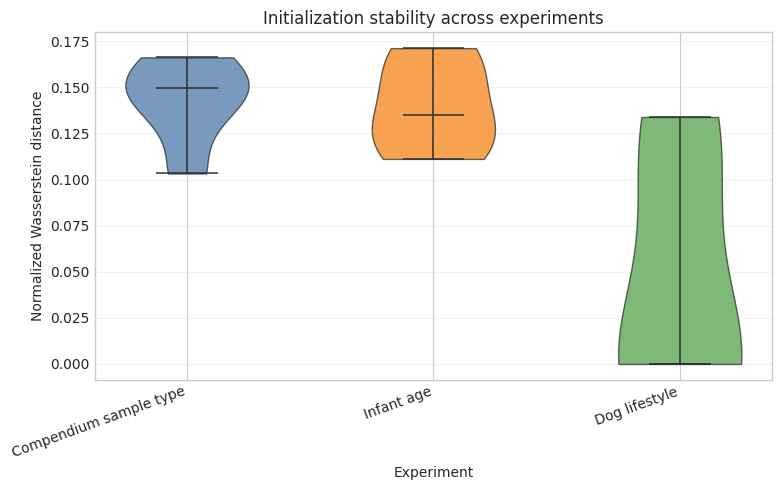

Mean normalized Wasserstein distances for initialization runs:
Compendium sample type: 0.1426 ± 0.0236
Infant age: 0.1395 ± 0.0251
Dog lifestyle: 0.0486 ± 0.0670
Overall mean: 0.1102 ± 0.0605


In [8]:
labels = list(EXPERIMENTS.values())
groups = [
    initialization_runs.loc[
        initialization_runs["experiment_label"].eq(label),
        "normalized_wasserstein_distance",
    ].to_numpy()
    for label in labels
]

fig, ax = plt.subplots(figsize=(8, 5))
parts = ax.violinplot(groups, showmedians=True, showextrema=True)
for body, label in zip(parts["bodies"], labels):
    body.set_facecolor(PALETTE[label])
    body.set_edgecolor("#2F2F2F")
    body.set_alpha(0.75)
for key in ["cmedians", "cmins", "cmaxes", "cbars"]:
    parts[key].set_color("#2F2F2F")
    parts[key].set_linewidth(1.1)

ax.set_xticks(np.arange(1, len(labels) + 1))
ax.set_xticklabels(labels, rotation=20, ha="right")
ax.set_ylabel("Normalized Wasserstein distance")
ax.set_xlabel("Experiment")
ax.set_title("Initialization stability across experiments")
ax.grid(True, axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

print("Mean normalized Wasserstein distances for initialization runs:")
for label in labels:
    mean_distance = initialization_runs.loc[
        initialization_runs["experiment_label"].eq(label),
        "normalized_wasserstein_distance",
    ].mean()
    std_distance = initialization_runs.loc[
        initialization_runs["experiment_label"].eq(label),
        "normalized_wasserstein_distance",
    ].std()
    print(f"{label}: {mean_distance:.4f} ± {std_distance:.4f}")
print(f"Overall mean: {initialization_runs['normalized_wasserstein_distance'].mean():.4f} ± {initialization_runs['normalized_wasserstein_distance'].std():.4f}")

## 2. Sampling Wasserstein violin subplots

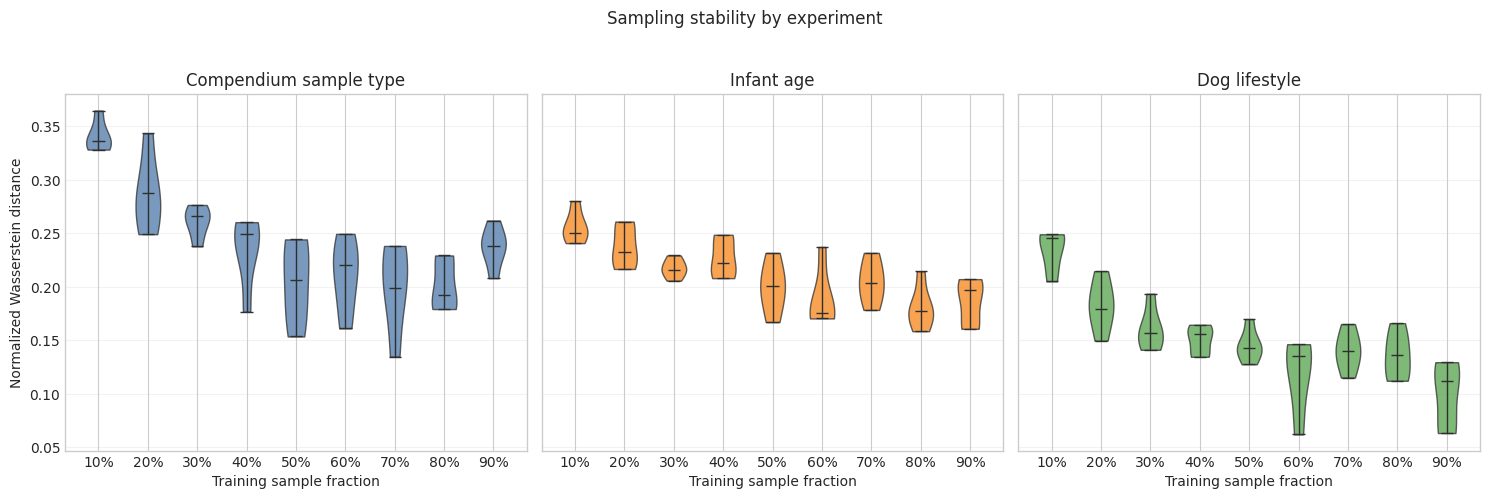

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)

for ax, (experiment, label) in zip(axes, EXPERIMENTS.items()):
    frame = sampling_runs.loc[sampling_runs["experiment"].eq(experiment)].copy()
    fractions = sorted(frame["fraction"].dropna().unique())
    groups = [
        frame.loc[np.isclose(frame["fraction"], fraction), "normalized_wasserstein_distance"].to_numpy()
        for fraction in fractions
    ]
    positions = np.arange(1, len(fractions) + 1)
    parts = ax.violinplot(groups, positions=positions, showmedians=True, showextrema=True)
    for body in parts["bodies"]:
        body.set_facecolor(PALETTE[label])
        body.set_edgecolor("#2F2F2F")
        body.set_alpha(0.75)
    for key in ["cmedians", "cmins", "cmaxes", "cbars"]:
        parts[key].set_color("#2F2F2F")
        parts[key].set_linewidth(1.0)
    ax.set_title(label)
    ax.set_xlabel("Training sample fraction")
    ax.set_xticks(positions)
    ax.set_xticklabels([f"{int(round(f * 100))}%" for f in fractions])
    ax.grid(True, axis="y", alpha=0.25)

axes[0].set_ylabel("Normalized Wasserstein distance")
fig.suptitle("Sampling stability by experiment", y=1.03)
fig.tight_layout()
plt.show()


## Prediction score tables

Each table keeps only the model family and the two score columns used for that experiment type.

In [5]:
def prediction_table_for_experiment(experiment):
    frame = prediction_scores.loc[
        prediction_scores["experiment"].eq(experiment) & prediction_scores["status"].eq("ok")
    ].copy()
    if frame.empty:
        return frame

    target_type = frame["target_type"].dropna().iloc[0]
    if target_type == "continuous":
        columns = ["family", "r2_mean", "mae_mean"]
    else:
        columns = ["family", "balanced_accuracy_mean", "macro_f1_mean"]

    table = frame[columns].copy()
    for column in columns[1:]:
        table[column] = table[column].round(3)
    return table

prediction_tables = {}
for experiment, label in EXPERIMENTS.items():
    print(label)
    table = prediction_table_for_experiment(experiment)
    prediction_tables[experiment] = table
    display(table)


Compendium sample type


,family,balanced_accuracy_mean,macro_f1_mean
0,aa,0.835,0.828
1,aa,0.823,0.820
2,baseline,0.754,0.750
3,benchmark,0.900,0.897
4,benchmark,0.915,0.915
6,benchmark,0.755,0.729


Infant age


,family,r2_mean,mae_mean
7,aa,0.581,7.565
8,aa,0.581,7.565
9,baseline,-5.665,13.473
10,benchmark,0.600,7.579
11,benchmark,0.597,7.680
13,benchmark,0.558,7.743


Dog lifestyle


,family,balanced_accuracy_mean,macro_f1_mean
14,aa,0.728,0.713
15,aa,0.713,0.695
16,baseline,0.745,0.731
17,benchmark,0.769,0.770
18,benchmark,0.805,0.803
20,benchmark,0.694,0.685


## 3. Prediction performance bar charts

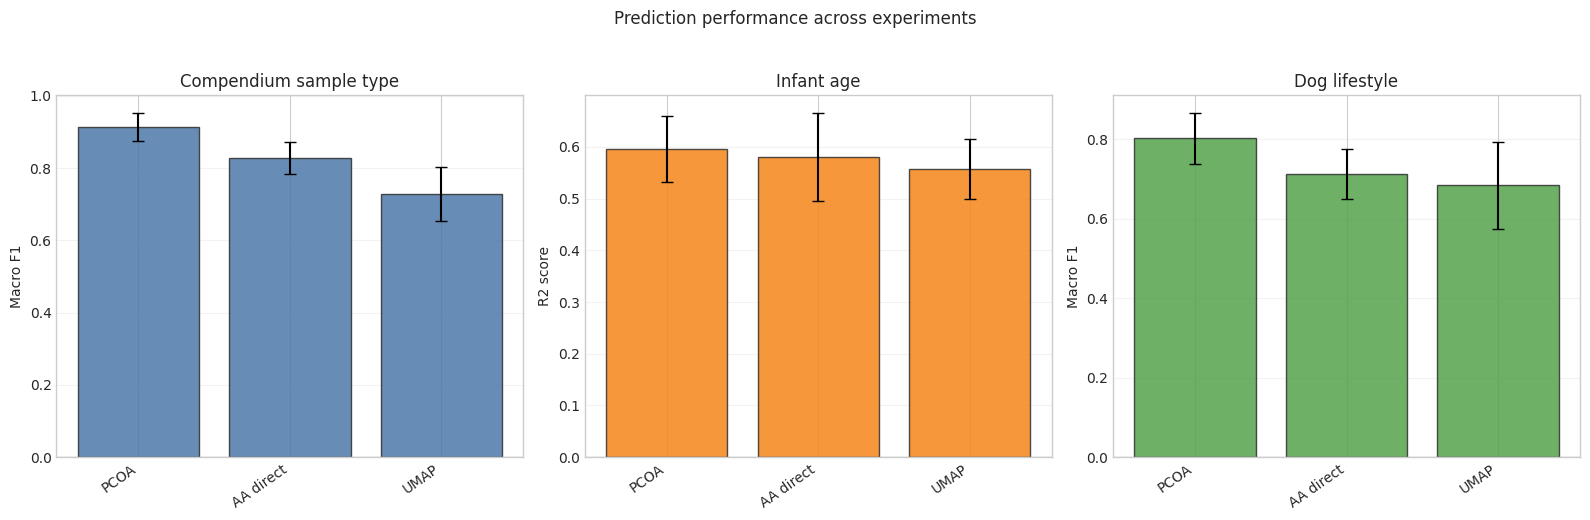

In [6]:
def bar_metric_for(frame):
    target_type = frame["target_type"].dropna().iloc[0]
    if target_type == "continuous":
        return "r2_mean", "r2_std", "R2 score"
    return "macro_f1_mean", "macro_f1_std", "Macro F1"

include=["archetypal_analysis_direct", "pcoa", "umap"]
def method_label(row):
    method = str(row["method"])
    replacements = {
        "archetypal_analysis_direct": "AA direct",
        "archetypal_analysis_helmert": "AA Helmert",
        "raw_input": "Raw input",
    }
    return replacements.get(method, method.upper() if method in {"pca", "pcoa", "tsne", "umap"} else method)

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=False)

for ax, (experiment, label) in zip(axes, EXPERIMENTS.items()):
    frame = prediction_scores.loc[
        prediction_scores["experiment"].eq(experiment) & prediction_scores["status"].eq("ok")
    ].copy()
    metric, error_metric, ylabel = bar_metric_for(frame)
    frame = frame.sort_values(metric, ascending=False).reset_index(drop=True)
    frame = frame.loc[frame["method"].isin(include)].copy()
    x = np.arange(len(frame))

    ax.bar(
        x,
        frame[metric],
        yerr=frame[error_metric],
        capsize=4,
        color=PALETTE[label],
        edgecolor="#2F2F2F",
        alpha=0.85,
    )
    ax.axhline(0, color="#2F2F2F", linewidth=0.8)
    ax.set_title(label)
    ax.set_ylabel(ylabel)
    ax.set_xticks(x)
    ax.set_xticklabels(frame.apply(method_label, axis=1), rotation=35, ha="right")
    ax.grid(True, axis="y", alpha=0.25)

fig.suptitle("Prediction performance across experiments", y=1.03)
fig.tight_layout()
plt.show()


## Held-out projection metrics

For each experiment and sampling fraction, these panels show the held-out projection metric mean with standard deviation error bars.

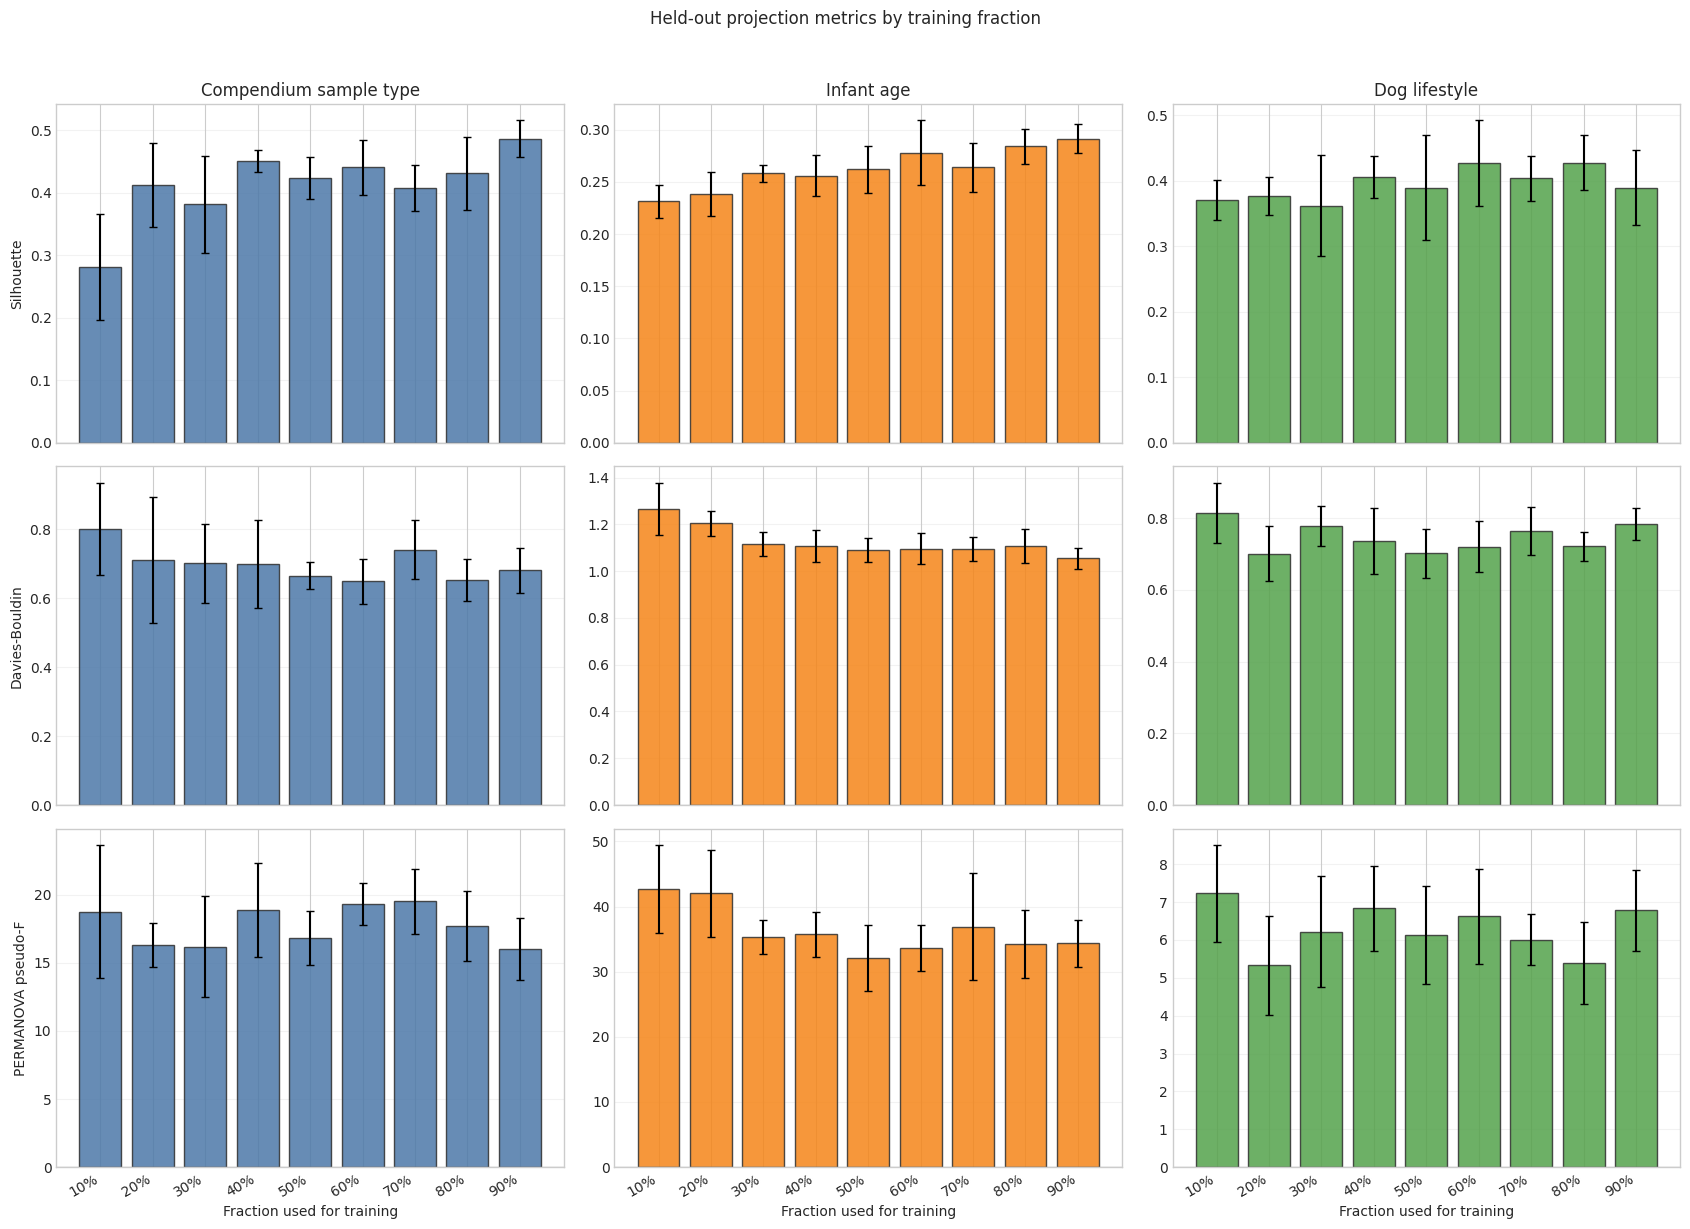

In [7]:
def load_heldout_projection_metrics():
    frames = []
    for experiment, label in EXPERIMENTS.items():
        path = RESULTS_DIR / experiment / "08_stability" / "heldout_projection_metrics.tsv"
        frame = read_tsv(path)
        frame["experiment"] = experiment
        frame["experiment_label"] = label
        frame["fraction"] = pd.to_numeric(frame["fraction"], errors="coerce")
        for metric in ["silhouette", "davies_bouldin", "metadata_permanova"]:
            frame[metric] = pd.to_numeric(frame[metric], errors="coerce")
        frames.append(frame)
    return pd.concat(frames, ignore_index=True).dropna(subset=["fraction"])
heldout_projection_metrics = load_heldout_projection_metrics()

METRICS = {
    "silhouette": "Silhouette",
    "davies_bouldin": "Davies-Bouldin",
    "metadata_permanova": "PERMANOVA pseudo-F",
}

fig, axes = plt.subplots(len(METRICS), len(EXPERIMENTS), figsize=(17, 12), sharex="col")

for col, (experiment, experiment_label) in enumerate(EXPERIMENTS.items()):
    heldout = heldout_projection_metrics.loc[
        heldout_projection_metrics["experiment"].eq(experiment)
    ].copy()
    fractions = sorted(heldout["fraction"].dropna().unique())

    for row, (metric, metric_label) in enumerate(METRICS.items()):
        ax = axes[row, col]
        summary = (
            heldout.groupby("fraction", as_index=False)[metric]
            .agg(heldout_mean="mean", heldout_std="std")
            .set_index("fraction")
            .reindex(fractions)
        )
        values = summary["heldout_mean"].to_numpy(dtype=float)
        errors = summary["heldout_std"].fillna(0).to_numpy(dtype=float)
        labels = [f"{int(round(f * 100))}%" for f in fractions]
        colors = [PALETTE[experiment_label]] * len(fractions)
        x = np.arange(len(labels))

        ax.bar(
            x,
            values,
            yerr=errors,
            capsize=3,
            color=colors,
            edgecolor="#2F2F2F",
            alpha=0.85,
        )
        ax.axhline(0, color="#2F2F2F", linewidth=0.8)
        ax.set_xticks(x)
        ax.set_xticklabels(labels, rotation=30, ha="right")
        ax.grid(True, axis="y", alpha=0.25)
        if row == 0:
            ax.set_title(experiment_label)
        if col == 0:
            ax.set_ylabel(metric_label)
        if row == len(METRICS) - 1:
            ax.set_xlabel("Fraction used for training")

fig.suptitle("Held-out projection metrics by training fraction", y=1.02)
fig.tight_layout()
plt.show()
